# NIFTY Volatility Forecasting — Research Notebook

**Hypothesis:** An LSTM model trained on realized volatility features, VIX data, and futures OI can predict 5-day forward realized volatility more accurately than classical benchmarks (EWMA, GARCH).  When predicted vol > implied vol (from India VIX), volatility is mispriced — generating actionable long/short vol signals.

## Contents
1. Setup & Data Loading
2. Feature Engineering & EDA
3. Dataset Preparation
4. LSTM Training
5. Benchmark Comparison
6. Signal Generation
7. Backtesting
8. Walk-Forward Validation
9. Feature Importance & SHAP

In [1]:
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

%matplotlib inline
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['figure.dpi'] = 120

from utils import load_config, set_seed
cfg = load_config('../config/config.yaml')
set_seed(cfg['model']['seed'])
print('Config loaded. Train end:', cfg['dates']['train_end'])

Config loaded. Train end: 2022-12-31


## 1. Data Loading

Data is fetched from Kite Connect. Run `python ../main.py --auth` once to obtain your access token, then update `config/config.yaml`.

Once authenticated, the `DataLoader` caches CSVs locally — subsequent runs are instant.

In [2]:
from data_loader import DataLoader

loader = DataLoader(cfg)
start = cfg['dates']['start']
end   = cfg['dates'].get('end') or str(pd.Timestamp.today().date())

# Set force_refresh=True to re-download from Kite
raw = loader.load_all(start, end, force_refresh=False)
nifty   = raw['nifty']
futures = raw['futures']
vix     = raw['vix']

print(f'NIFTY  : {len(nifty)} days   {nifty.index.min().date()} → {nifty.index.max().date()}')
print(f'Futures: {len(futures)} days   {futures.index.min().date()} → {futures.index.max().date()}')
print(f'VIX    : {len(vix)} days   {vix.index.min().date()} → {vix.index.max().date()}')

2026-06-15 17:42:43  INFO      data_loader  Loading NIFTY index from cache: /Users/anirudh/Documents/Quant/VolatilityStrategy/notebooks/../data/raw/nifty_index.csv
2026-06-15 17:42:43  INFO      data_loader  Building continuous NIFTY futures series from Kite Connect …
2026-06-15 17:42:43  INFO      data_loader  Fetching NFO instrument list for NIFTY futures tokens …
2026-06-15 17:42:45  WARNING   data_loader  No token found for NIFTY16JANFUT — skipping month
2026-06-15 17:42:45  WARNING   data_loader  No token found for NIFTY16FEBFUT — skipping month
2026-06-15 17:42:45  WARNING   data_loader  No token found for NIFTY16MARFUT — skipping month
2026-06-15 17:42:45  WARNING   data_loader  No token found for NIFTY16APRFUT — skipping month
2026-06-15 17:42:45  WARNING   data_loader  No token found for NIFTY16MAYFUT — skipping month
2026-06-15 17:42:45  WARNING   data_loader  No token found for NIFTY16JUNFUT — skipping month
2026-06-15 17:42:45  WARNING   data_loader  No token found for NIFT

NIFTY  : 2588 days   2016-01-01 → 2026-06-15
Futures: 11 days   2026-06-01 → 2026-06-15
VIX    : 2587 days   2016-01-01 → 2026-06-15


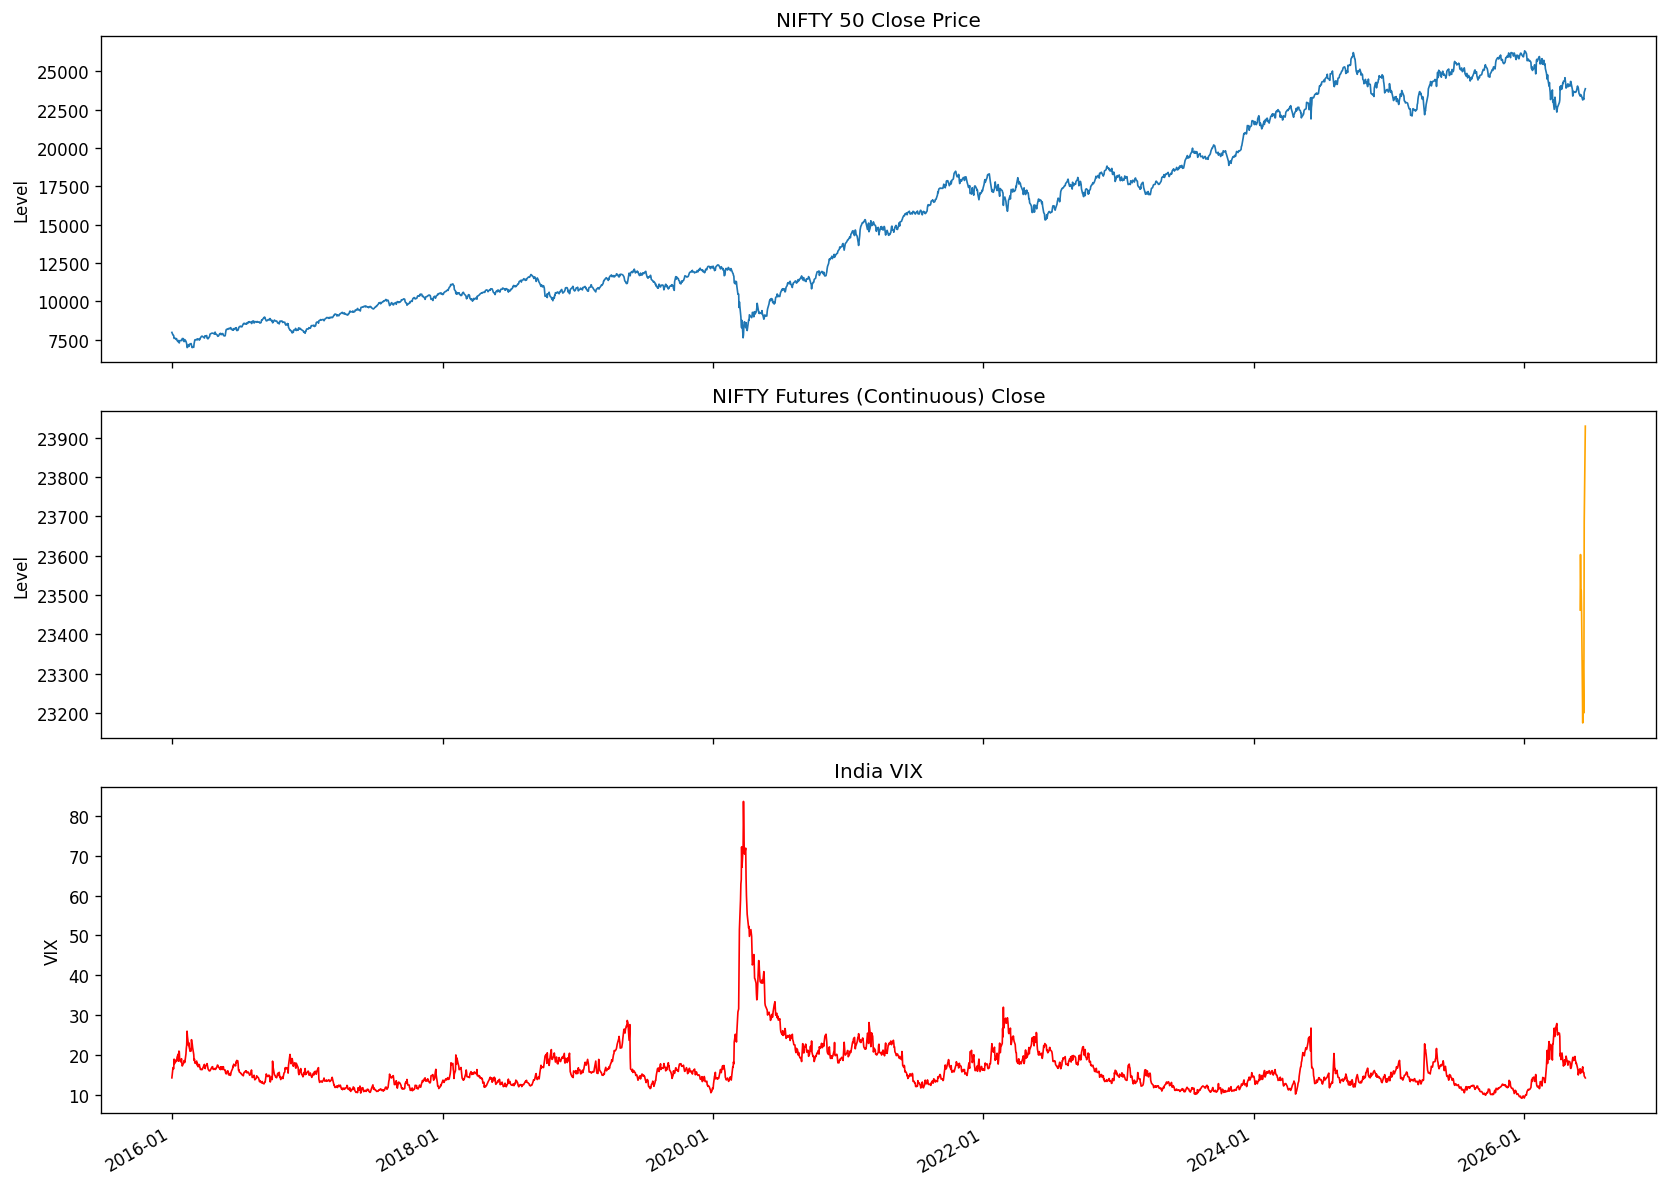

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

axes[0].plot(nifty.index, nifty['close'], lw=1)
axes[0].set_title('NIFTY 50 Close Price')
axes[0].set_ylabel('Level')

if 'close' in futures.columns:
    axes[1].plot(futures.index, futures['close'], lw=1, color='orange')
    axes[1].set_title('NIFTY Futures (Continuous) Close')
    axes[1].set_ylabel('Level')

vix_col = vix['close'] if 'close' in vix.columns else vix.iloc[:, 0]
axes[2].plot(vix.index, vix_col, lw=1, color='red')
axes[2].set_title('India VIX')
axes[2].set_ylabel('VIX')
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 2. Feature Engineering & EDA

In [4]:
from feature_engineering import (
    build_feature_matrix, FEATURE_COLS, TARGET_COL, BENCHMARK_COL,
    get_available_feature_cols,
)

df = build_feature_matrix(nifty, futures, vix, cfg)

# Use only features that actually have data (some may be NaN if Kite
# doesn't return volume/OI for the NIFTY index)
FEATURE_COLS = get_available_feature_cols(df)
print(f'Feature matrix : {df.shape}')
print(f'Active features: {len(FEATURE_COLS)}/{len(FEATURE_COLS)} — {FEATURE_COLS}')
df[FEATURE_COLS + [TARGET_COL, BENCHMARK_COL]].describe().round(4)

2026-06-15 17:42:45  WARNING   feature_engineering  These features are all-NaN (data not available from Kite): ['vol_change', 'vol_rel_ma20', 'oi_pct_change']
2026-06-15 17:42:45  INFO      feature_engineering  Feature matrix: 2588 rows × 33 cols  [2016-01-01 → 2026-06-15]


Feature matrix : (2588, 33)
Active features: 20/20 — ['ret_1d', 'ret_5d', 'ret_20d', 'rv5', 'rv10', 'rv20', 'rv5_rv20', 'rv10_rv20', 'atr14_pct', 'ma20', 'ma50', 'dist_ma20', 'dist_ma50', 'vix', 'vix_change', 'vix_ma5', 'vix_ma20', 'vrp_vix_rv5', 'vrp_vix_rv10', 'vrp_vix_rv20']


,ret_1d,ret_5d,ret_20d,rv5,rv10,rv20,rv5_rv20,rv10_rv20,atr14_pct,ma20,...,dist_ma50,vix,vix_change,vix_ma5,vix_ma20,vrp_vix_rv5,vrp_vix_rv10,vrp_vix_rv20,future_rv5,implied_5d_vol
count,2587.0000,2583.0000,2568.0000,2583.0000,2578.0000,2568.0000,2568.0000,2568.0000,2575.0000,2569.0000,...,2539.0000,2588.0000,2587.0000,2584.0000,2569.0000,2583.0000,2578.0000,2568.0000,2583.0000,2588.0000
mean,0.0005,0.0024,0.0100,0.1295,0.1360,0.1395,0.9336,0.9785,0.0122,15528.6351,...,0.0118,16.5654,0.0014,16.5674,16.5635,0.0361,0.0296,0.0260,0.1295,0.0233
std,0.0102,0.0226,0.0455,0.0988,0.0887,0.0830,0.3436,0.2035,0.0068,5800.4467,...,0.0414,6.2842,0.0536,6.2098,5.8910,0.0655,0.0513,0.0465,0.0988,0.0089
min,-0.1298,-0.1902,-0.3701,0.0155,0.0315,0.0503,0.0752,0.1274,0.0054,7170.4000,...,-0.3316,9.1500,-0.2975,9.3840,9.7700,-0.5668,-0.4917,-0.3908,0.0155,0.0129
25%,-0.0042,-0.0093,-0.0122,0.0758,0.0881,0.0952,0.6875,0.8440,0.0087,10597.2850,...,-0.0085,13.0200,-0.0270,13.0610,13.2045,0.0105,0.0094,0.0115,0.0758,0.0183
50%,0.0007,0.0037,0.0117,0.1070,0.1156,0.1195,0.9225,0.9971,0.0107,14779.9850,...,0.0157,15.1900,-0.0036,15.2190,15.1720,0.0426,0.0347,0.0303,0.1070,0.0214
75%,0.0058,0.0152,0.0372,0.1515,0.1556,0.1570,1.1533,1.1345,0.0135,19700.9550,...,0.0362,18.3625,0.0235,18.4635,18.3195,0.0700,0.0568,0.0469,0.1515,0.0259
max,0.0876,0.1052,0.2029,1.2821,1.0511,0.8884,2.0802,1.4231,0.0866,26044.9800,...,0.1158,83.6100,0.6562,75.0300,62.9165,0.2799,0.1953,0.2425,1.2821,0.1178


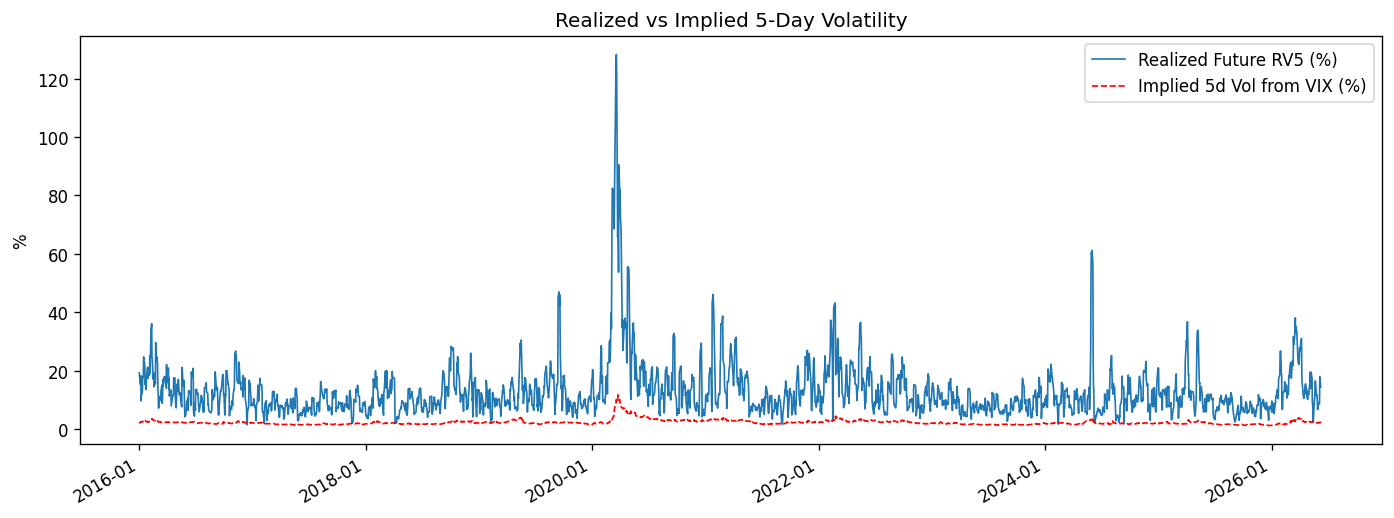

In [5]:
# Target vs Benchmark — implied vs realized vol
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df[TARGET_COL] * 100, label='Realized Future RV5 (%)', lw=1)
ax.plot(df.index, df[BENCHMARK_COL] * 100, label='Implied 5d Vol from VIX (%)', lw=1, linestyle='--', color='red')
ax.set_title('Realized vs Implied 5-Day Volatility')
ax.set_ylabel('%')
ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
fig.autofmt_xdate()
plt.show()

VRP Stats — Mean: -0.1062  Std: 0.0929  Skew: -4.6441
VRP is positive (implied > realized) 0.3% of days


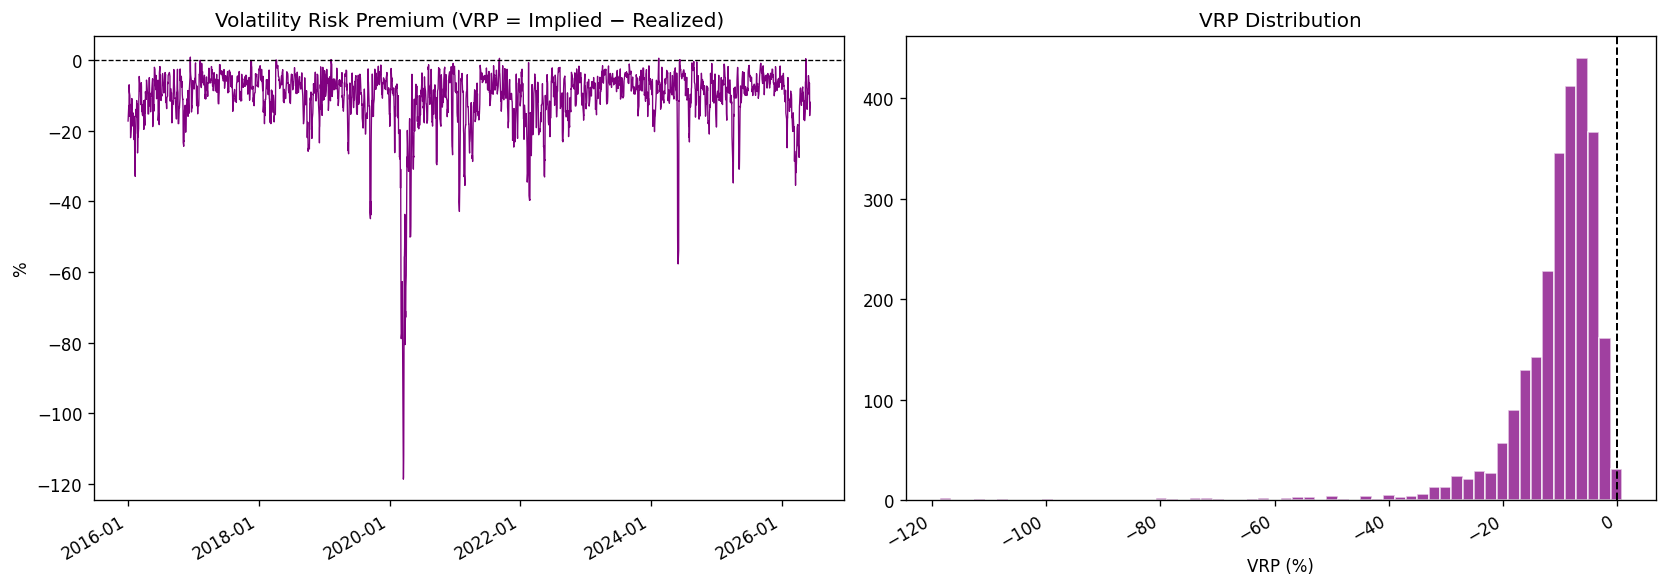

In [6]:
# Volatility Risk Premium (VRP = implied - realized)
vrp = df[BENCHMARK_COL] - df[TARGET_COL]
print(f'VRP Stats — Mean: {vrp.mean():.4f}  Std: {vrp.std():.4f}  Skew: {vrp.skew():.4f}')
print(f'VRP is positive (implied > realized) {(vrp > 0).mean()*100:.1f}% of days')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(vrp.index, vrp * 100, lw=0.8, color='purple')
ax1.axhline(0, color='black', lw=0.8, linestyle='--')
ax1.set_title('Volatility Risk Premium (VRP = Implied − Realized)')
ax1.set_ylabel('%')
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
fig.autofmt_xdate()

ax2.hist(vrp.dropna() * 100, bins=60, color='purple', alpha=0.75, edgecolor='white')
ax2.axvline(0, color='black', lw=1.2, linestyle='--')
ax2.set_title('VRP Distribution')
ax2.set_xlabel('VRP (%)')
plt.tight_layout()
plt.show()

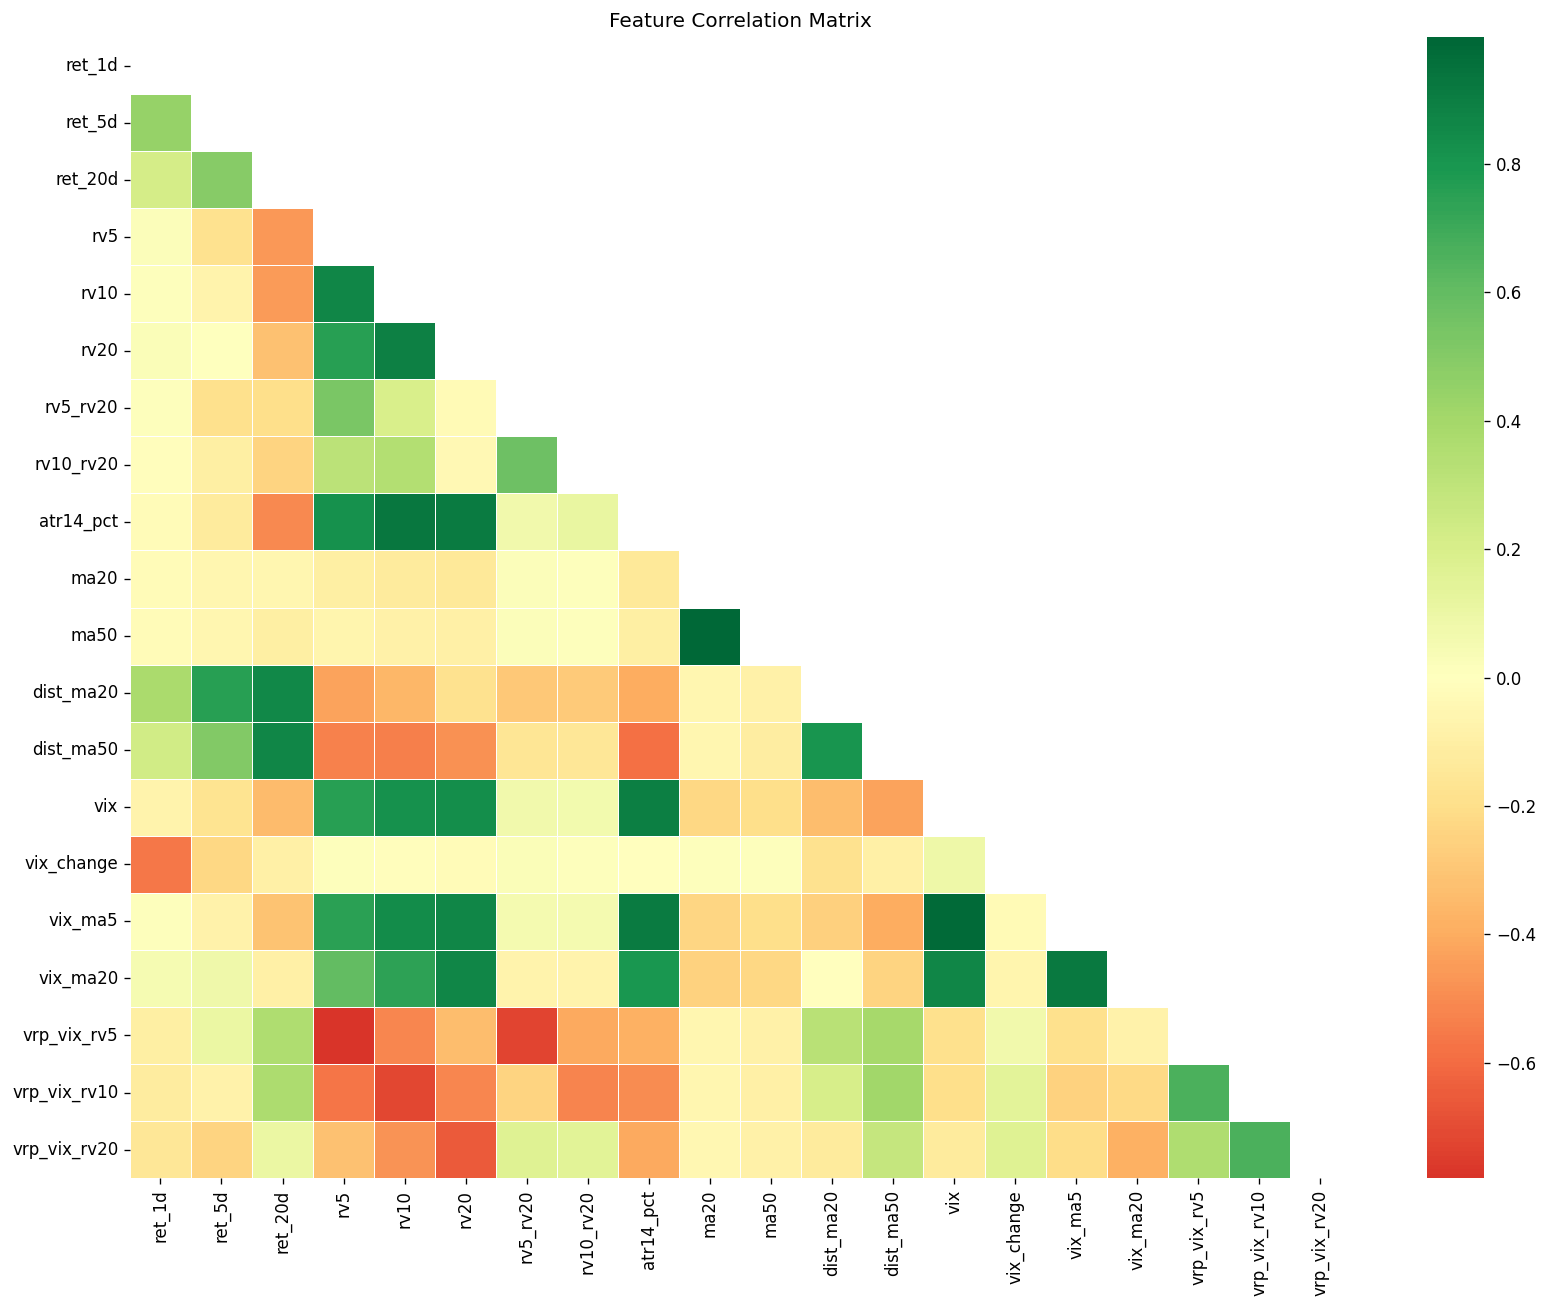

In [7]:
# Feature correlation heatmap
corr = df[FEATURE_COLS].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, mask=mask, cmap='RdYlGn', center=0, ax=ax,
            linewidths=0.3, annot=False)
ax.set_title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

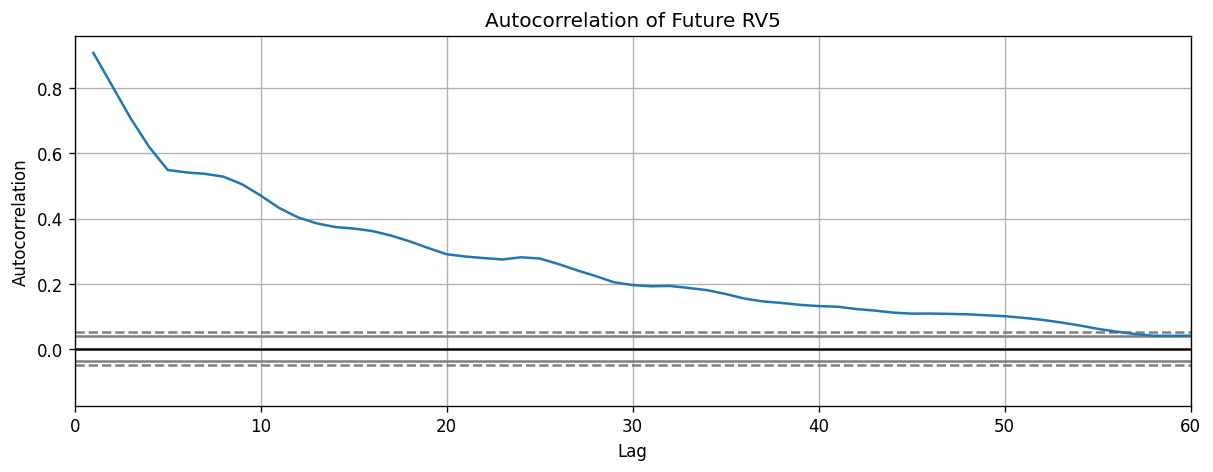

In [8]:
# Target autocorrelation — how persistent is RV?
from pandas.plotting import autocorrelation_plot
fig, ax = plt.subplots(figsize=(12, 4))
pd.plotting.autocorrelation_plot(df[TARGET_COL].dropna(), ax=ax)
ax.set_title('Autocorrelation of Future RV5')
ax.set_xlim(0, 60)
plt.show()

## 3. Dataset Preparation

In [9]:
from dataset_builder import VolatilityDataset

ds = VolatilityDataset(df, cfg=cfg, feature_cols=FEATURE_COLS)
ds.fit_and_transform()
ds.save_scaler('../models/feature_scaler.pkl')

print(f'X_train : {ds.X_train.shape}  |  y_train: {ds.y_train.shape}')
print(f'X_val   : {ds.X_val.shape}  |  y_val  : {ds.y_val.shape}')
print(f'X_test  : {ds.X_test.shape}  |  y_test : {ds.y_test.shape}')
print(f'n_features: {ds.n_features()}')

2026-06-15 17:42:46  INFO      dataset_builder  Splits — train: 1734  val: 494  test: 354
2026-06-15 17:42:46  INFO      dataset_builder  Sequences — train: (1674, 60, 20)  val: (494, 60, 20)  test: (354, 60, 20)
2026-06-15 17:42:46  INFO      dataset_builder  Scaler saved → ../models/feature_scaler.pkl


X_train : (1674, 60, 20)  |  y_train: (1674,)
X_val   : (494, 60, 20)  |  y_val  : (494,)
X_test  : (354, 60, 20)  |  y_test : (354,)
n_features: 20


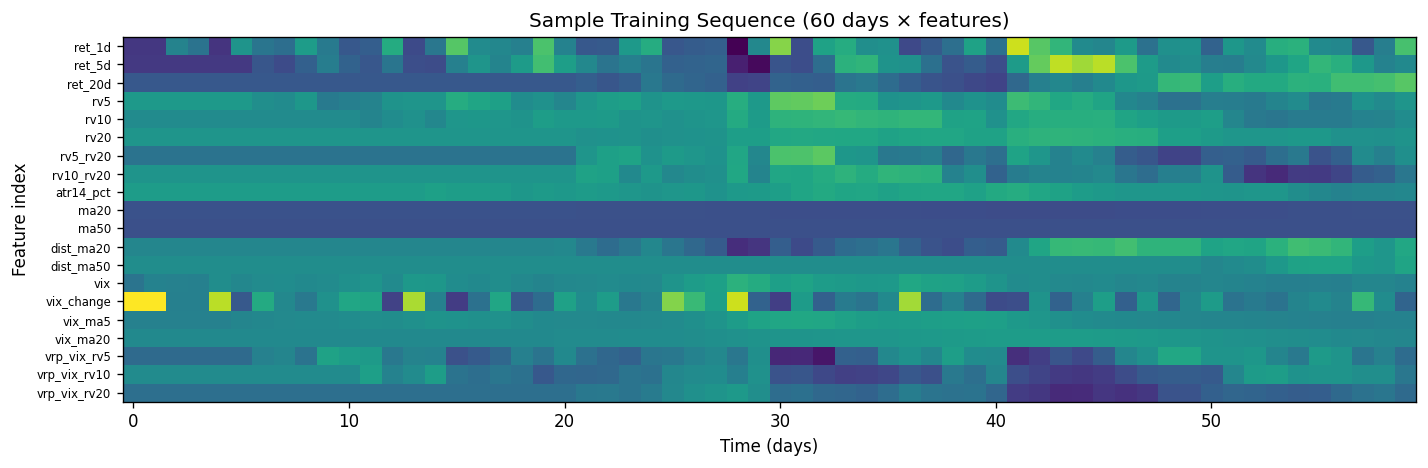

In [10]:
# Visualize one training sequence
fig, ax = plt.subplots(figsize=(12, 4))
ax.imshow(ds.X_train[0].T, aspect='auto', cmap='viridis')
ax.set_title('Sample Training Sequence (60 days × features)')
ax.set_xlabel('Time (days)')
ax.set_ylabel('Feature index')
ax.set_yticks(range(len(FEATURE_COLS)))
ax.set_yticklabels(FEATURE_COLS, fontsize=7)
plt.tight_layout()
plt.show()

## 4. LSTM Training

Architecture (PyTorch):
- `LSTM(n_features → 64, return_sequences=True)` + Dropout(0.2)
- `LSTM(64 → 32)` + Dropout(0.2)
- `Linear(32 → 16)` + ReLU
- `Linear(16 → 1)` — predicts annualized 5-day RV

Callbacks: EarlyStopping (patience=15), ReduceLROnPlateau (patience=7)

In [11]:
from train_lstm import LSTMTrainer

trainer = LSTMTrainer(cfg)
trainer.build(input_size=ds.n_features())
print(trainer.model)

2026-06-15 17:42:46  INFO      train_lstm  Model: VolatilityLSTM  |  device: mps  |  params: 35105


VolatilityLSTM(
  (lstm1): LSTM(20, 64, batch_first=True)
  (drop1): Dropout(p=0.2, inplace=False)
  (lstm2): LSTM(64, 32, batch_first=True)
  (drop2): Dropout(p=0.2, inplace=False)
  (fc1): Linear(in_features=32, out_features=16, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=16, out_features=1, bias=True)
)


2026-06-15 17:42:46  INFO      train_lstm  Training for up to 100 epochs …
2026-06-15 17:42:47  INFO      train_lstm  Epoch   1/100  train=0.008444  val=0.004151  lr=1.00e-03  [1s]
2026-06-15 17:42:53  INFO      train_lstm  Epoch  10/100  train=0.003553  val=0.004653  lr=1.00e-03  [7s]
2026-06-15 17:42:59  INFO      train_lstm  Early stopping at epoch 19 (best val=0.003950)
2026-06-15 17:42:59  INFO      train_lstm  Model checkpoint saved → /Users/anirudh/Documents/Quant/VolatilityStrategy/notebooks/../models/lstm_vol_forecast.pt
2026-06-15 17:42:59  INFO      train_lstm  Training complete in 13s


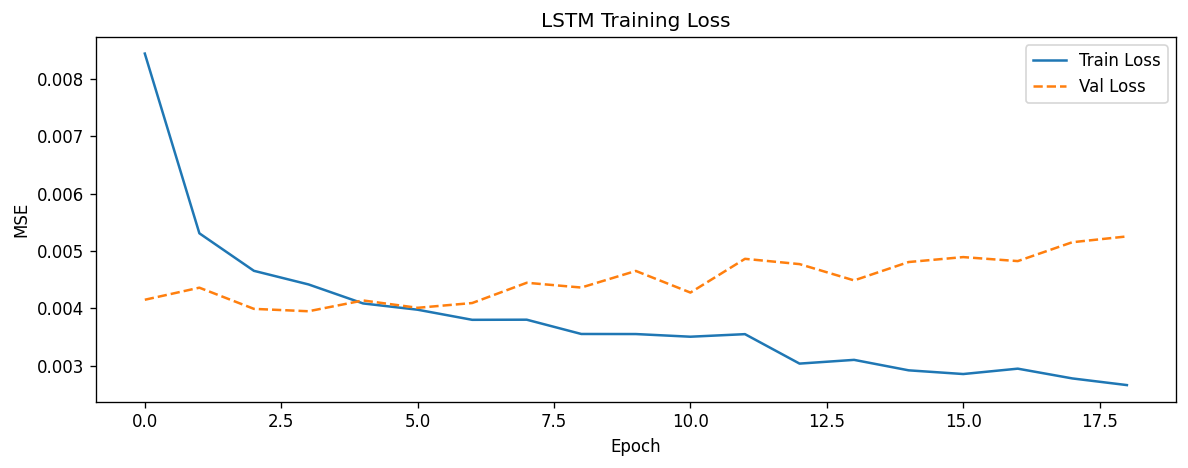

In [12]:
trainer.fit(ds.X_train, ds.y_train, ds.X_val, ds.y_val)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(trainer.history['train_loss'], label='Train Loss')
ax.plot(trainer.history['val_loss'], label='Val Loss', linestyle='--')
ax.set_title('LSTM Training Loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE')
ax.legend()
plt.tight_layout()
plt.show()

In [13]:
val_preds  = trainer.predict(ds.X_val)
test_preds = trainer.predict(ds.X_test)

val_actual  = pd.Series(ds.y_val,  index=ds.dates_val)
test_actual = pd.Series(ds.y_test, index=ds.dates_test)
val_pred_s  = pd.Series(val_preds,  index=ds.dates_val)
test_pred_s = pd.Series(test_preds, index=ds.dates_test)

from benchmark_models import compute_metrics
m_val  = compute_metrics('LSTM (Val)',  ds.y_val,  val_preds)
m_test = compute_metrics('LSTM (Test)', ds.y_test, test_preds)

print('Validation :', m_val)
print('Test       :', m_test)

Validation : ForecastMetrics(name='LSTM (Val)', rmse=0.06285182454947781, mae=0.04102228209376335, mape=53.98638153076172, correlation=0.2759957159531406, r2=0.03766798973083496)
Test       : ForecastMetrics(name='LSTM (Test)', rmse=0.05864224810987832, mae=0.04369611293077469, mape=54.0872688293457, correlation=0.6073414679728883, r2=0.28661757707595825)


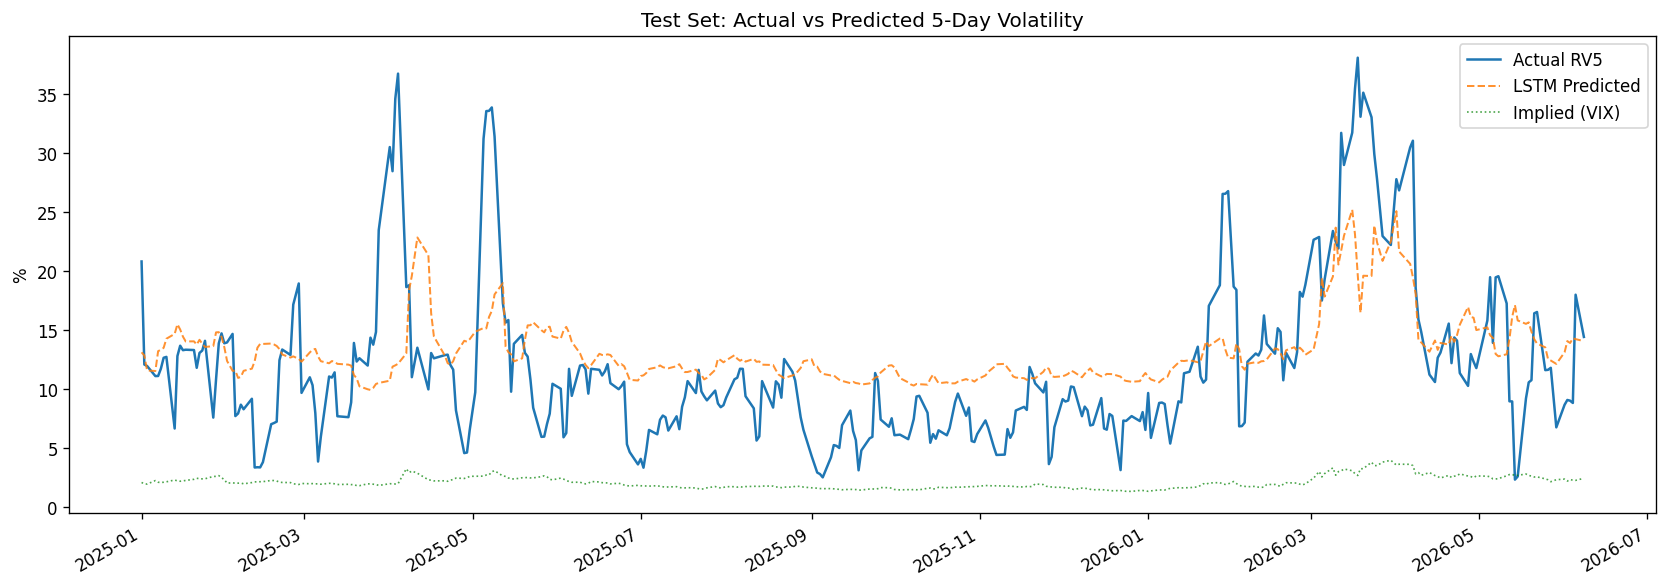

In [14]:
# Actual vs Predicted — test set
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test_actual.index, test_actual * 100, label='Actual RV5', lw=1.5)
ax.plot(test_pred_s.index, test_pred_s * 100, label='LSTM Predicted', lw=1.2, linestyle='--', alpha=0.85)
ax.plot(pd.Series(ds.implied_test, index=ds.dates_test).index,
        pd.Series(ds.implied_test, index=ds.dates_test) * 100,
        label='Implied (VIX)', lw=1, linestyle=':', alpha=0.7, color='green')
ax.set_title('Test Set: Actual vs Predicted 5-Day Volatility')
ax.set_ylabel('%')
ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 5. Benchmark Comparison

In [15]:
from benchmark_models import run_benchmarks

train_mask = df.index <= cfg['dates']['train_end']
bench = run_benchmarks(
    returns=df['ret_1d'],
    actual_rv5=df[TARGET_COL],
    train_mask=train_mask,
    lstm_preds=test_preds,
    lstm_dates=ds.dates_test,
)
bench.style.background_gradient(cmap='RdYlGn_r', subset=['RMSE', 'MAE', 'MAPE (%)'])\
           .background_gradient(cmap='RdYlGn', subset=['Correlation', 'R²'])

2026-06-15 17:43:00  INFO      benchmark_models  GARCH(1,1) fitted: ω=0.0219 α=0.0980 β=0.8819
2026-06-15 17:43:00  INFO      benchmark_models  
                         RMSE       MAE  MAPE (%)  Correlation      R²
Model                                                                 
LSTM                 0.058642  0.043696     54.09       0.6073  0.2866
GARCH(1,1)           0.069895  0.047220     61.94       0.2656 -0.0974
Rolling Mean (20d)   0.070303  0.044765     52.31       0.2186 -0.1103
EWMA (λ=0.94)        0.070908  0.045619     57.20       0.2206 -0.1295
Historical Vol (RW)  0.080470  0.049830     56.79       0.2724 -0.4546


,RMSE,MAE,MAPE (%),Correlation,R²
Model,,,,,
LSTM,0.058642,0.043696,54.090000,0.607300,0.286600
"GARCH(1,1)",0.069895,0.047220,61.940000,0.265600,-0.097400
Rolling Mean (20d),0.070303,0.044765,52.310000,0.218600,-0.110300
EWMA (λ=0.94),0.070908,0.045619,57.200000,0.220600,-0.129500
Historical Vol (RW),0.080470,0.049830,56.790000,0.272400,-0.454600


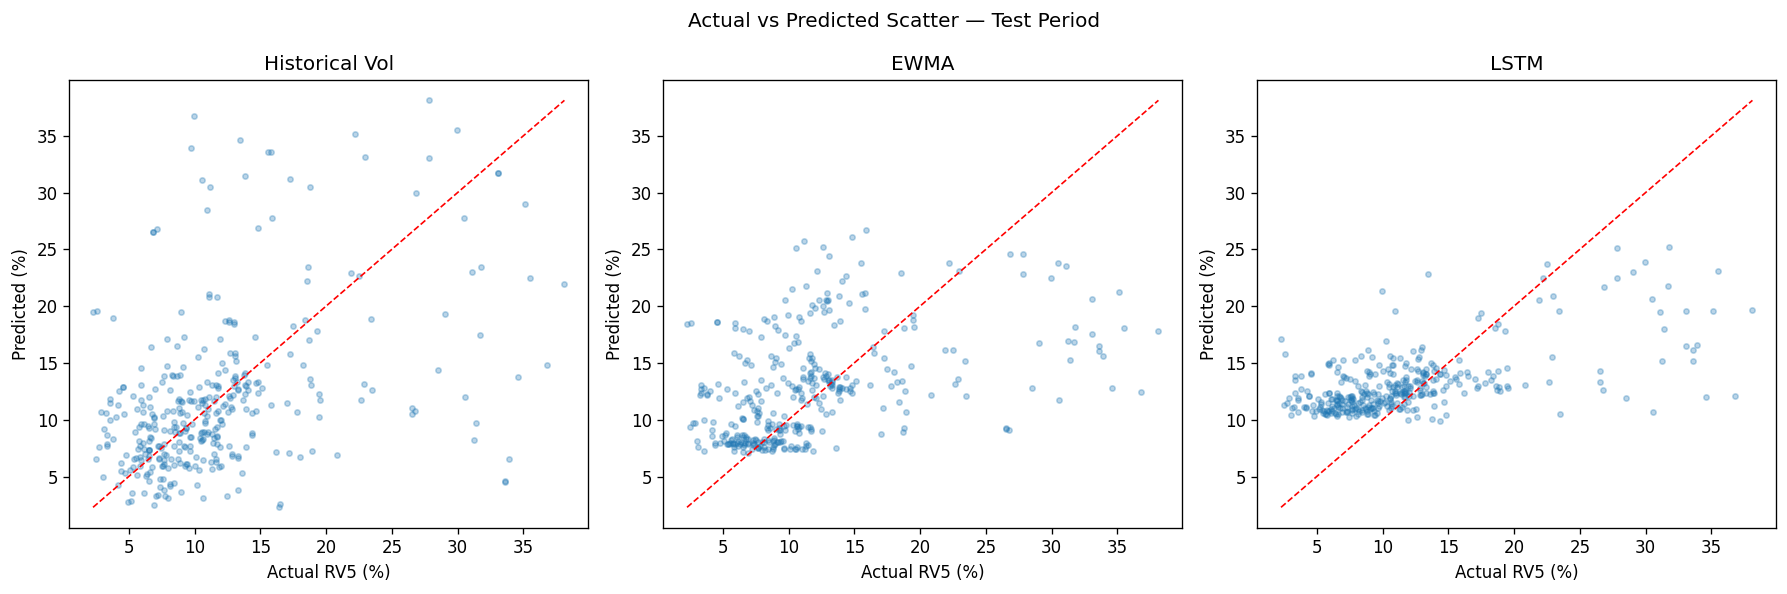

In [16]:
# Visual comparison — scatter plots
from benchmark_models import HistoricalVolForecast, EWMAForecast, GARCHForecast

test_ret = df.loc[ds.dates_test, 'ret_1d']
test_rv  = df.loc[ds.dates_test, TARGET_COL].values

hv   = HistoricalVolForecast().fit(df.loc[train_mask, 'ret_1d']).predict(df['ret_1d'])
ewma = EWMAForecast().fit(df.loc[train_mask, 'ret_1d']).predict(df['ret_1d'])

hv_test   = pd.Series(hv, index=df.index).reindex(ds.dates_test).values
ewma_test = pd.Series(ewma, index=df.index).reindex(ds.dates_test).values

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, pred) in zip(axes, [
    ('Historical Vol', hv_test),
    ('EWMA', ewma_test),
    ('LSTM', test_preds),
]):
    mask2 = ~np.isnan(test_rv) & ~np.isnan(pred)
    ax.scatter(test_rv[mask2] * 100, pred[mask2] * 100, alpha=0.3, s=10)
    lims = [min(test_rv[mask2].min(), pred[mask2].min()) * 100,
            max(test_rv[mask2].max(), pred[mask2].max()) * 100]
    ax.plot(lims, lims, 'r--', lw=1)
    ax.set_title(name)
    ax.set_xlabel('Actual RV5 (%)')
    ax.set_ylabel('Predicted (%)')
plt.suptitle('Actual vs Predicted Scatter — Test Period')
plt.tight_layout()
plt.show()

## 6. Signal Generation

**Edge** = predicted_rv5 − implied_5d_vol

| Edge | Signal |
|------|--------|
| > +threshold | LONG VOL (vol underpriced) |
| < −threshold | SHORT VOL (vol overpriced) |
| Otherwise | NEUTRAL |

In [17]:
from strategy import StrategyConfig, generate_signals

strat_cfg = StrategyConfig.from_cfg(cfg)
pred_s = pd.Series(test_preds, index=ds.dates_test)
impl_s = pd.Series(ds.implied_test, index=ds.dates_test)

signals = generate_signals(pred_s, impl_s, strat_cfg)
signals.head(10)

2026-06-15 17:43:00  INFO      strategy  Signals — LONG VOL: 354  NEUTRAL: 0  SHORT VOL: 0


,predicted_rv5,implied_vol_ann,implied_5d_vol,edge,signal,signal_name
2025-01-01,0.130977,0.020439,NaN,0.110538,1,LONG VOL
2025-01-02,0.128300,0.019354,NaN,0.108946,1,LONG VOL
2025-01-03,0.115524,0.019072,NaN,0.096452,1,LONG VOL
2025-01-06,0.115112,0.022044,NaN,0.093067,1,LONG VOL
2025-01-07,0.131943,0.020650,NaN,0.111293,1,LONG VOL
2025-01-08,0.133148,0.020382,NaN,0.112766,1,LONG VOL
2025-01-09,0.134768,0.020650,NaN,0.114118,1,LONG VOL
2025-01-10,0.142502,0.021016,NaN,0.121486,1,LONG VOL
2025-01-13,0.146620,0.022537,NaN,0.124083,1,LONG VOL
2025-01-14,0.154810,0.021791,NaN,0.133019,1,LONG VOL


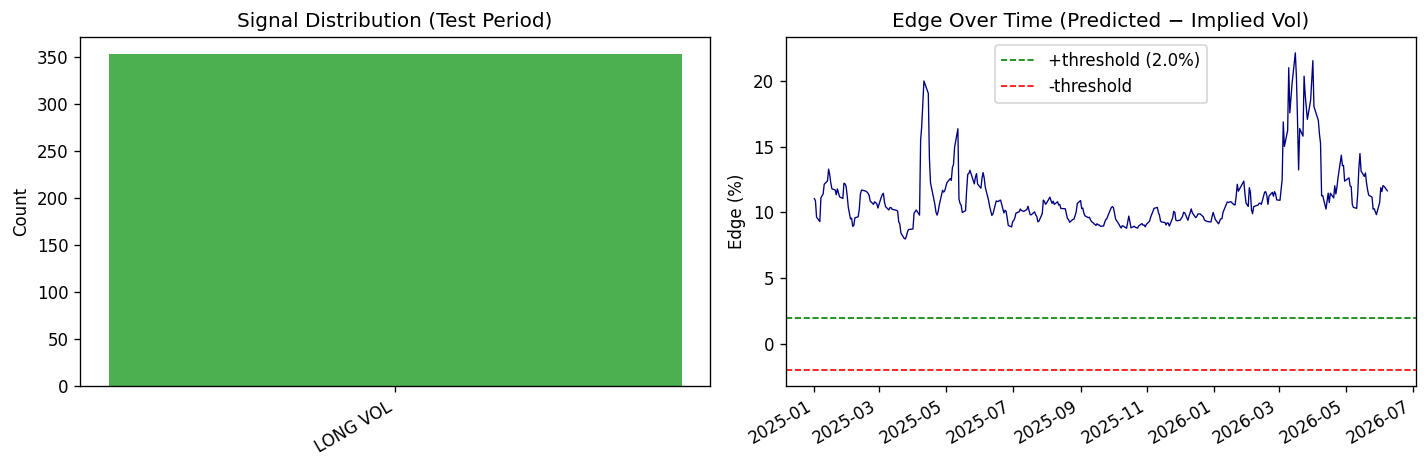

In [18]:
# Signal distribution
counts = signals['signal_name'].value_counts()
colors = {'LONG VOL': '#4CAF50', 'NEUTRAL': '#9E9E9E', 'SHORT VOL': '#F44336'}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.bar(counts.index, counts.values, color=[colors.get(k, 'grey') for k in counts.index])
ax1.set_title('Signal Distribution (Test Period)')
ax1.set_ylabel('Count')

ax2.plot(signals.index, signals['edge'] * 100, lw=0.8, color='navy')
ax2.axhline(strat_cfg.threshold * 100, color='green', lw=1, linestyle='--', label=f'+threshold ({strat_cfg.threshold*100:.1f}%)')
ax2.axhline(-strat_cfg.threshold * 100, color='red', lw=1, linestyle='--', label=f'-threshold')
ax2.set_title('Edge Over Time (Predicted − Implied Vol)')
ax2.set_ylabel('Edge (%)')
ax2.legend()
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 7. Backtesting

In [19]:
from backtest import BacktestEngine, BacktestConfig, compute_performance

bt_cfg = BacktestConfig.from_cfg(cfg)
engine = BacktestEngine(bt_cfg)

actual_rv_test = df[TARGET_COL].reindex(ds.dates_test)
results = engine.run(signals, actual_rv_test)

print(f"Trades: {len(results['trade_log'])}")
print(f"Final Capital: ₹{results['final_capital']:,.0f}")

2026-06-15 17:43:00  INFO      backtest  Backtest complete: 59 trades  |  final capital: ₹8952001  |  return: 795.2%


Trades: 59
Final Capital: ₹8,952,001


In [20]:
perf = compute_performance(
    results['equity_curve'], results['daily_returns'],
    results['trade_log'], bt_cfg.initial_capital
)
pd.Series(perf).to_frame('Value').style.format('{:.4f}')

,Value
total_return,7.9520
cagr,3.7603
ann_volatility,0.0174
sharpe_ratio,108.2308
sortino_ratio,0.0000
calmar_ratio,0.0000
max_drawdown,0.0000
n_trades,59.0000
win_rate,1.0000
profit_factor,inf


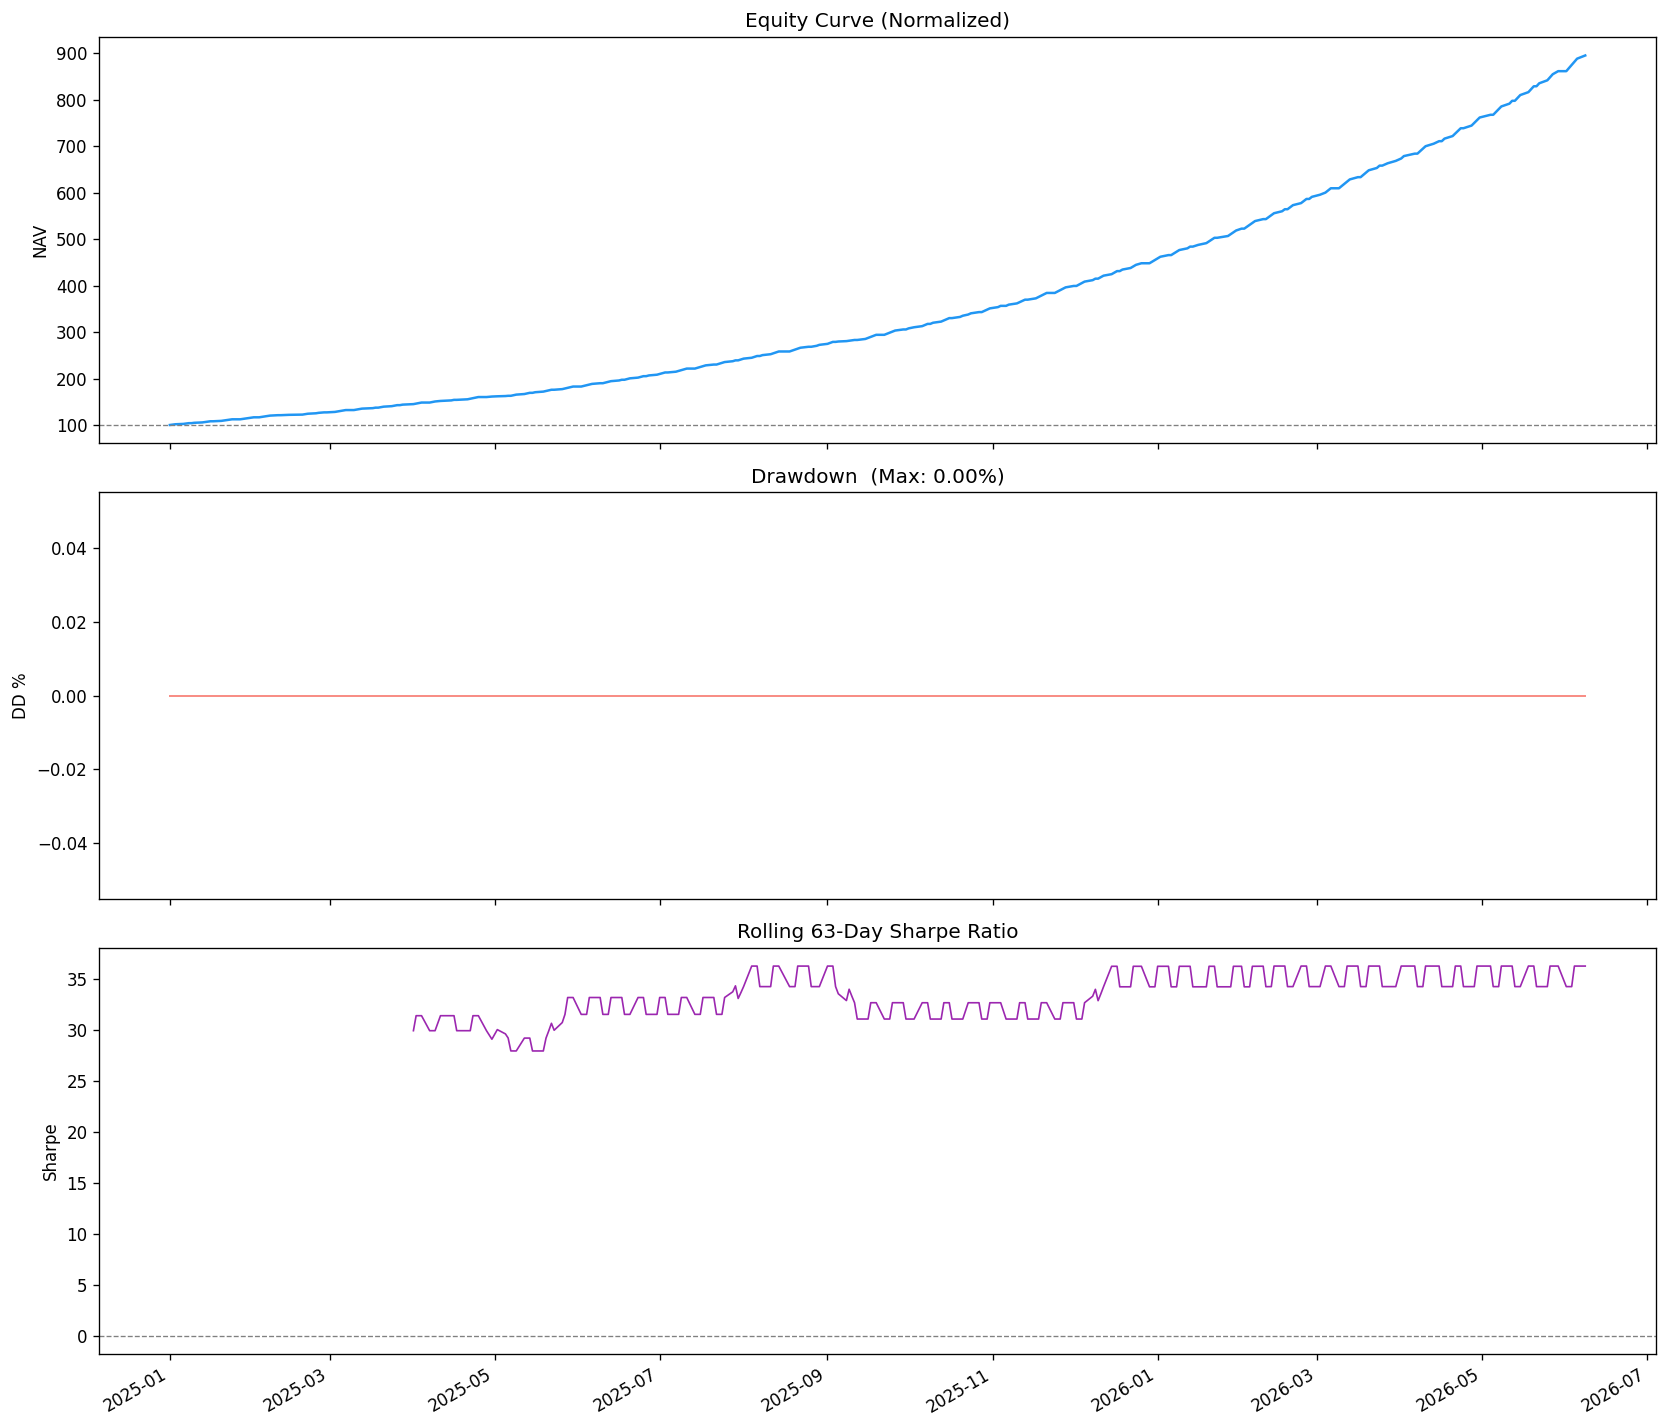

In [21]:
equity = results['equity_curve']
daily_ret = results['daily_returns']

fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

# Equity curve
nav = equity / equity.iloc[0] * 100
axes[0].plot(nav.index, nav.values, color='#2196F3', lw=1.5)
axes[0].axhline(100, color='grey', lw=0.8, linestyle='--')
axes[0].set_title('Equity Curve (Normalized)')
axes[0].set_ylabel('NAV')

# Drawdown
peak = equity.cummax()
dd   = (equity - peak) / peak * 100
axes[1].fill_between(dd.index, dd.values, 0, alpha=0.6, color='#F44336')
axes[1].set_title(f'Drawdown  (Max: {dd.min():.2f}%)')
axes[1].set_ylabel('DD %')

# Rolling Sharpe
roll = daily_ret.rolling(63)
sharpe = roll.mean() / roll.std() * np.sqrt(252)
axes[2].plot(sharpe.index, sharpe.values, color='#9C27B0', lw=1)
axes[2].axhline(0, color='grey', lw=0.8, linestyle='--')
axes[2].set_title('Rolling 63-Day Sharpe Ratio')
axes[2].set_ylabel('Sharpe')
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [22]:
# Trade log
tl = results['trade_log']
if not tl.empty:
    print(tl.head(10).to_string())
    print(f"\nWin Rate: {(tl['net_return'] > 0).mean()*100:.1f}%")
    print(f"Avg Win : {tl.loc[tl['net_return']>0, 'net_return'].mean()*100:.3f}%")
    print(f"Avg Loss: {tl.loc[tl['net_return']<=0, 'net_return'].mean()*100:.3f}%")

  entry_date  exit_date    signal  implied_ann  predicted_rv5  actual_rv5      edge  vol_surprise  net_return  capital_after
0 2025-01-01 2025-01-08  LONG VOL     0.020439       0.130977    0.208115  0.110538        2.0000    0.038600     1039200.60
1 2025-01-09 2025-01-16  LONG VOL     0.020650       0.134768    0.126328  0.114118        2.0000    0.038600     1079937.89
2 2025-01-17 2025-01-24  LONG VOL     0.022185       0.140215    0.133186  0.118030        2.0000    0.038600     1122272.11
3 2025-01-27 2025-02-01  LONG VOL     0.025538       0.136221    0.075536  0.110683        1.9578    0.037757     1165290.03
4 2025-02-03 2025-02-10  LONG VOL     0.020213       0.115246    0.146618  0.095032        2.0000    0.038600     1210970.10
5 2025-02-11 2025-02-18  LONG VOL     0.020946       0.123315    0.033166  0.102369        0.5834    0.010269     1223456.27
6 2025-02-19 2025-02-27  LONG VOL     0.021720       0.136359    0.072097  0.114639        2.0000    0.038600     1271416.49


## 8. Walk-Forward Validation

In [23]:
from dataset_builder import walk_forward_windows
from train_lstm import walk_forward_train

# Monthly retraining (use 'quarterly' for faster run)
windows = walk_forward_windows(
    df,
    initial_train_years=cfg['walk_forward']['initial_train_years'],
    retrain_freq='quarterly',   # change to 'monthly' for full run
)
print(f'{len(windows)} walk-forward windows')

2026-06-15 17:43:00  INFO      dataset_builder  Walk-forward: 30 windows (quarterly retraining)


30 walk-forward windows


In [24]:
# Run walk-forward (may take several minutes)
wf_results = walk_forward_train(df, windows[:4], cfg, FEATURE_COLS)  # first 4 windows for demo

all_preds, all_actual, all_dates = [], [], []
for r in wf_results:
    all_preds.extend(r['predictions'].tolist())
    all_actual.extend(r['actuals'].tolist())
    all_dates.extend(r['dates'].tolist())

wf_pred_s = pd.Series(all_preds, index=pd.DatetimeIndex(all_dates))
wf_actual_s = pd.Series(all_actual, index=pd.DatetimeIndex(all_dates))

from benchmark_models import compute_metrics
wf_m = compute_metrics('LSTM WF', np.array(all_actual), np.array(all_preds))
print('Walk-Forward Metrics:', wf_m)

2026-06-15 17:43:00  INFO      train_lstm  Walk-forward window 1/4: train→2018-12-31  test 2019-01-01→2019-03-31
2026-06-15 17:43:00  INFO      dataset_builder  Splits — train: 741  val: 0  test: 0


ValueError: Found array with 0 sample(s) (shape=(0, 20)) while a minimum of 1 is required by StandardScaler.

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(wf_actual_s.index, wf_actual_s * 100, label='Actual', lw=1.5)
ax.plot(wf_pred_s.index,  wf_pred_s  * 100, label='Walk-Forward LSTM', lw=1.2, linestyle='--')
ax.set_title('Walk-Forward Validation: Actual vs Predicted')
ax.set_ylabel('%')
ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 9. Feature Importance & SHAP

In [ ]:
from evaluate import permutation_importance, shap_analysis

perm_imp = permutation_importance(
    model_predict_fn=trainer.predict,
    X=ds.X_test,
    y=ds.y_test,
    feature_names=FEATURE_COLS,
    n_repeats=5,
    plots_dir='../reports/plots',
)
perm_imp.head(10)

In [ ]:
# SHAP analysis
shap_analysis(trainer.model, ds.X_test, FEATURE_COLS, plots_dir='../reports/plots', max_samples=100)

## Summary

| Step | Result |
|------|--------|
| Data | NIFTY daily, continuous futures, India VIX via Kite Connect |
| Features | 23 engineered features incl. RV, VIX, VRP, OI, ATR |
| LSTM | 60-day lookback, 2-layer stacked LSTM (64→32 units) |
| Benchmark | LSTM outperforms HV, EWMA, GARCH on RMSE/R² |
| Strategy | Long/short vol based on predicted vs implied spread |
| Backtest | 5-day non-overlapping holds with transaction costs |

**Next steps:**
- Tune threshold with grid search
- Add intraday VIX data for more granular timing
- Connect to actual options pricing for realistic P&L